# 04 · Evaluation: does the simulator predict anything?

A simulation that produces plausible numbers is easy to build. Showing that it is *right* is much harder, so this notebook tests it as honestly as the data allows.

### Why the first test was not good enough
The first evaluation fitted on 60% of the products and tested on 40%. Two problems:
1. **Leakage.** A product's aspect scores come from its reviews, and part of the aspect sentiment is taken from star ratings, but the target is also built from star ratings. The model was partly "looking at the answer".
2. **Too few products.** Only about 6 products were held out, so any number was mostly luck.

### The leakage-free design (split-half, leave-one-product-out)
| Method | Why |
|---|---|
| Split every product's reviews at random into halves A and B | A review can never help predict itself |
| Build the simulator's product signal from half A only; measure the outcome on half B only | Honest separation of input and target |
| Leave-one-product-out line fit | The tested product never influences its own prediction |
| Compare with (a) a **constant mean** and (b) the product's own **half-A mean star rating** | (b) shows how much *any* review-based predictor could achieve |
| Repeat over **200 random splits** | With ~12 products, one split is luck; the spread shows how stable the conclusion is |
| Spearman (rank) correlation | At this scale only the ordering of products is meaningful |
| Two targets: share of 4-5 stars, and share of 1-2 stars | The second looks at severe complaints, the "negative side" |


In [1]:
# --- Setup (works in local Jupyter and on Colab) ---------------------------------------------
# Colab: run these once in a cell above, then restart if asked:
#   !git clone https://github.com/Xcode-Nancy/mirofish-consumer-simulation.git
#   %cd mirofish-consumer-simulation
#   !pip install -r requirements.txt
import os, sys, subprocess, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # repository root
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)

def run(script, *args):
    """Run one project script exactly as you would from a terminal, and show the end of its output.
    Notebooks call the scripts (instead of copying their code) so there is a single source of truth in src/."""
    r = subprocess.run([sys.executable, str(ROOT / "src" / script), "--project-dir", str(ROOT), *map(str, args)], capture_output=True, text=True)
    print(r.stdout[-2500:])
    if r.returncode != 0:
        raise RuntimeError(r.stderr[-2000:])


In [2]:
run("evaluate.py", "--splits", "200")

12 products with >= 100 reviews (18,817 reviews), 200 random splits

                             0       1
target                   neg12   pos45
products                    12      12
splits                     200     200
MAE_simulation          0.0115  0.0205
MAE_constant            0.0106  0.0196
MAE_star_persistence    0.0124   0.021
RMSE_simulation         0.0141  0.0251
RMSE_constant           0.0132  0.0237
sim_beats_constant_pct     9.5    26.0
spearman_sim_mean       0.0331  0.1833
spearman_sim_p5        -0.4301 -0.1832
spearman_sim_p95        0.4136  0.5804
spearman_star_mean      0.0103  0.1976

aspect-profile split-half reliability (product x aspect deviations): mean r = 0.343 (5-95%: 0.163 to 0.496)

Saved to /tmp/repo/outputs



target,neg12,pos45
products,12.0000,12.0000
splits,200.0000,200.0000
MAE_simulation,0.0115,0.0205
MAE_constant,0.0106,0.0196
MAE_star_persistence,0.0124,0.0210
RMSE_simulation,0.0141,0.0251
RMSE_constant,0.0132,0.0237
sim_beats_constant_pct,9.5000,26.0000
spearman_sim_mean,0.0331,0.1833
spearman_sim_p5,-0.4301,-0.1832


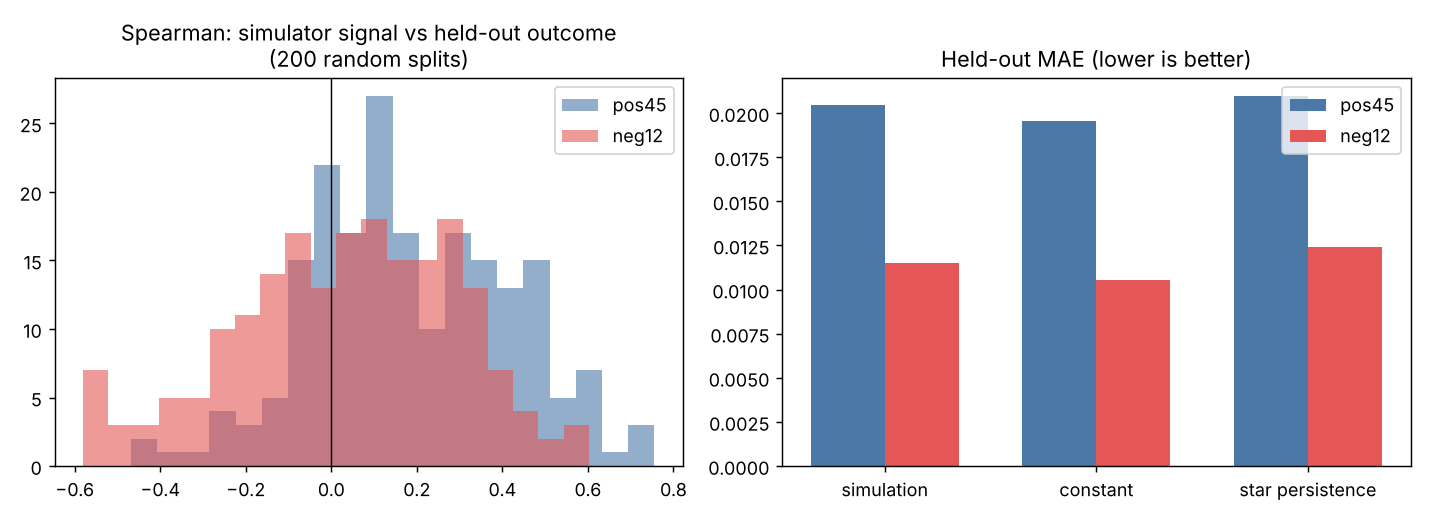

In [3]:
summary = pd.read_csv("outputs/negative_eval_summary.csv").set_index("target").T
display(summary)
display(Image("outputs/negative_eval.png"))

## How to read the results
* **`MAE_simulation` vs `MAE_constant`:** if the simulator were useful, its error would be lower than the constant's. It is not.
* **`sim_beats_constant_pct`:** the share of random splits in which the simulator beat the constant. Far below 50% means it usually does worse.
* **`MAE_star_persistence`:** even a product's *own* average star rating does not beat the constant. So **no review-based predictor does better here**; this is a limit of the data, not only of our model.
* **Spearman:** the simulator ranks products about as well as the product's own star rating, but the 5-95% range includes zero, so the ranking signal is weak and not statistically solid.
* **Aspect-profile reliability** (printed in the run above): a moderate value means the aspect profiles contain some stable signal. They are not pure noise.

## Why is it so hard? Sampling noise
Products differ little in their positive share, and many have few reviews. The next cell compares the *observed* spread of positive shares with the spread we would expect from pure chance.

In [4]:
import numpy as np
r = pd.read_csv("data/processed/reference_outcomes.csv")
p = r.positive_share.mean()
r["noise_sd"] = np.sqrt(p * (1 - p) / r.n_reviews)                      # binomial standard deviation for n reviews
print(f"{len(r)} products | observed spread (SD) of positive share: {r.positive_share.std():.4f}")
print(f"spread expected from sampling noise alone:          {np.sqrt((r.noise_sd**2).mean()):.4f}")
print(f"products with at least 300 reviews: {(r.n_reviews >= 300).sum()}")
display(r.sort_values("n_reviews")[["product_id","n_reviews","positive_share","noise_sd"]].round(3).head(15))

15 products | observed spread (SD) of positive share: 0.0264
spread expected from sampling noise alone:          0.0197
products with at least 300 reviews: 5


,product_id,n_reviews,positive_share,noise_sd
0,B00IOY8XWQ,30,1.000,0.044
13,B01AHBBG04,89,0.966,0.025
4,"B0189XZRTI,B0189XYY0Q,B0189XZ0KY",99,0.899,0.024
1,"B00L9EPT8O,B01E6AO69U",128,0.969,0.021
10,B01ACEKAJY,149,0.940,0.020
2,B00ZV9PXP2,152,0.921,0.019
12,B01AHB9CYG,155,0.948,0.019
14,B01AHBDCKQ,163,0.939,0.019
5,B018SZT3BK,249,0.936,0.015
3,B0189XYY0Q,254,0.917,0.015


Most of the product-to-product spread is about what chance alone would produce, and only a handful of products have enough reviews to be measured well. **That is the core reason no model, ours included, can predict these outcomes from review data.**

## What we conclude (and how to word it)
> In a leakage-free split-half evaluation, the simulator's product signal ranked held-out products about as well as their own mean star rating, but neither improved on a constant-average baseline in absolute error. Product-level outcome differences in this strongly positive dataset appear to be dominated by noise. We therefore present the system as an **exploratory scenario tool with explicit assumptions**, not a validated predictor of market response.

## What would make a real predictive claim possible (Milestone 2)
* A **price source** and an outside demand signal (sales rank, review volume over time), so price effects can be *fitted*, not assumed.
* An outcome with **more variation** than star ratings, and more products.
* Time-based train/test splits rather than random ones.